In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    f1_score,
)

In [2]:
iris = load_iris()
X = iris.data
y = iris.target
class_names = iris.target_names

df = pd.DataFrame(X, columns=iris.feature_names)
df["species"] = [class_names[i] for i in y]

In [3]:
print("First 5 rows:")
print(df.head(), "\n")
print("Shape (rows, columns):", df.shape)
print("\nSamples per class:")
print(df["species"].value_counts(), "\n")
print("Missing values:", df.isnull().sum().sum(), "\n")


First 5 rows:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa   

Shape (rows, columns): (150, 5)

Samples per class:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64 

Missing values: 0 



In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    shuffle=True,
    random_state=42,
    stratify=y,
)
print("Training samples:", len(X_train))
print("Testing samples: ", len(X_test), "\n")

Training samples: 120
Testing samples:  30 



In [6]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

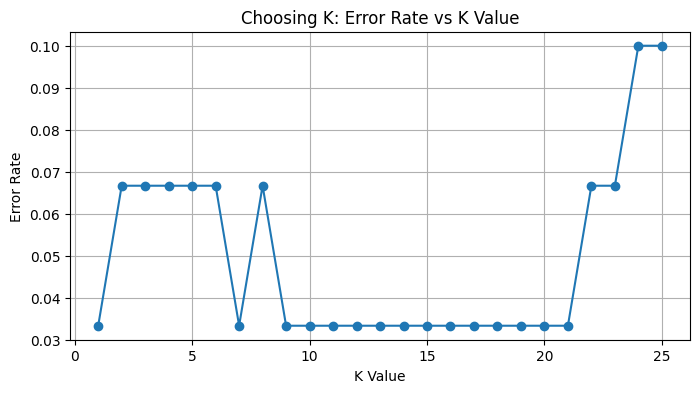

K with the lowest error: 1


In [7]:
k_values = range(1, 26)
error_rates = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    pred = knn.predict(X_test_scaled)
    error_rates.append(1 - accuracy_score(y_test, pred))

plt.figure(figsize=(8, 4))
plt.plot(k_values, error_rates, marker="o")
plt.title("Choosing K: Error Rate vs K Value")
plt.xlabel("K Value")
plt.ylabel("Error Rate")
plt.grid(True)
plt.show()

best_k = k_values[int(np.argmin(error_rates))]
print("K with the lowest error:", best_k)

In [8]:
model = KNeighborsClassifier(n_neighbors=5)
model.fit(X_train_scaled, y_train)
predictions = model.predict(X_test_scaled)

In [9]:
print("\nAccuracy:", round(accuracy_score(y_test, predictions), 4))
print("F1 Score (macro):", round(f1_score(y_test, predictions, average="macro"), 4))

print("\nClassification Report:")
print(classification_report(y_test, predictions, target_names=class_names))


Accuracy: 0.9333
F1 Score (macro): 0.9327

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



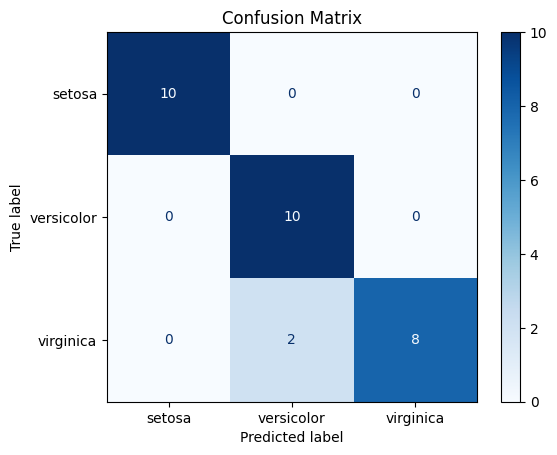

In [10]:
cm = confusion_matrix(y_test, predictions)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

In [11]:
new_flower = np.array([[5.1, 3.5, 1.4, 0.2]])  # sepal L, sepal W, petal L, petal W
new_flower_scaled = scaler.transform(new_flower)  # must be scaled the same way
result = model.predict(new_flower_scaled)
print("\nNew flower prediction:", class_names[result[0]])


New flower prediction: setosa
